## Which associations hold together

Notebook 1 showed that Kaiser share, across offered counties, lines up with income, poverty, the uninsured rate, unemployment, and Silver premiums. Those characteristics describe the same places. This notebook estimates them together.

The comparison is across counties. Each county Kaiser offered in 2016–2024 is one row, and each measure is the mean of the years it was offered. Monterey is not in the sample. Its service area opens in 2025. The outcome is `kp_market_share`. Log population is held constant, so a coefficient is not a restatement of county size.

Premiums are the age-40 individual Silver rate already used in the market mart. The benchmark is the county price level. Kaiser's premium is the lowest age-40 Silver rate among Kaiser standard components. The gap is that Kaiser rate minus the benchmark. Los Angeles has no single county premium, so it stays in the socioeconomic model and drops out when a premium enters.


In [1]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import HTML, Markdown, display
from statsmodels.stats.outliers_influence import variance_inflation_factor

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 11,
})

con = duckdb.connect("../data/processed/analysis.duckdb", read_only=True)
market = con.sql("select * from main_marts.mart_cty_yr_market").df()
performance = con.sql("select * from main_marts.mart_cty_yr_performance").df()
socioeconomic = con.sql("select * from main_marts.mart_cty_yr_socioeconomic").df()
kp_silver = con.sql("""
    select
        year,
        county_fips,
        min(plan_rate) as kp_lowest_silver
    from (
        select
            year,
            county_fips,
            standard_component_id,
            min(individual_rate_age_40) as plan_rate
        from main_intermediate.int_cms_plan_cty_yr
        where is_kp
          and metal_level = 'Silver'
          and individual_rate_age_40 is not null
        group by 1, 2, 3
    )
    group by 1, 2
""").df()

offered = (
    market
    .merge(performance, on=["county_fips", "year"], how="left", suffixes=("", "_performance"))
    .merge(socioeconomic, on=["county_fips", "year"], how="left", suffixes=("", "_socio"))
    .merge(kp_silver, on=["county_fips", "year"], how="left")
)
offered = offered[offered["kp_offered"] & offered["year"].between(2016, 2024)].copy()
offered["kp_silver_gap"] = offered["kp_lowest_silver"] - offered["benchmark_silver_premium"]

measure_cols = [
    "kp_market_share",
    "population_total",
    "median_household_income",
    "poverty_rate",
    "uninsured_rate",
    "unemployment_rate",
    "carrier_count",
    "benchmark_silver_premium",
    "kp_lowest_silver",
    "kp_silver_gap",
]
county = offered.groupby(["county_fips", "county_name"], as_index=False)[measure_cols].mean()
county["log_population"] = np.log(county["population_total"])
county["income_10k"] = county["median_household_income"] / 10000

gap = offered["kp_silver_gap"].dropna()
display(Markdown(
    f"The socioeconomic sample is **{county['county_fips'].nunique()} offered counties**. "
    f"Kaiser has an age-40 Silver premium in "
    f"**{offered.loc[offered['kp_silver_gap'].notna(), 'county_fips'].nunique()}** of them. "
    f"Across those county-years, Kaiser is below the benchmark in **{(gap < -0.5).mean():.0%}**, "
    f"at the benchmark in **{(gap.abs() <= 0.5).mean():.0%}**, "
    f"and above it in **{(gap > 0.5).mean():.0%}**. "
    "The median gap is "
    f"**${gap.median():.0f}**."
))


The socioeconomic sample is **32 offered counties**. Kaiser has an age-40 Silver premium in **31** of them. Across those county-years, Kaiser is below the benchmark in **36%**, at the benchmark in **34%**, and above it in **30%**. The median gap is **$0**.

## Shared variation

Income and poverty describe the same counties, and the benchmark premium moves with how Kaiser is priced against it. A variance inflation factor above 5 means a term is sharing its signal with the others. Model 3 is the specification that puts both premium terms in at once. Model 2 keeps the benchmark and leaves the gap out.


In [3]:
PREDICTORS = [
    "log_population",
    "income_10k",
    "poverty_rate",
    "uninsured_rate",
    "unemployment_rate",
    "carrier_count",
    "benchmark_silver_premium",
    "kp_silver_gap",
]
LABELS = {
    "log_population": "Log population",
    "income_10k": "Median income",
    "poverty_rate": "Poverty rate",
    "uninsured_rate": "Uninsured rate",
    "unemployment_rate": "Unemployment rate",
    "carrier_count": "Carrier count",
    "benchmark_silver_premium": "Benchmark Silver premium",
    "kp_silver_gap": "Kaiser premium minus benchmark",
}
MODEL_2 = [
    "log_population",
    "income_10k",
    "poverty_rate",
    "uninsured_rate",
    "unemployment_rate",
    "carrier_count",
    "benchmark_silver_premium",
]
MODEL_3 = MODEL_2 + ["kp_silver_gap"]

premium_counties = county.dropna(subset=PREDICTORS).copy()
corr = premium_counties[PREDICTORS].corr().rename(index=LABELS, columns=LABELS).round(2)
display(Markdown(
    f"Predictor correlations across the **{len(premium_counties)} counties** with a premium. "
    "Los Angeles is omitted."
))
display(HTML(corr.to_html()))


def vif_table(frame, columns, specification):
    scaled = frame[columns].apply(lambda series: (series - series.mean()) / series.std(ddof=0))
    design = sm.add_constant(scaled)
    rows = []
    for position, name in enumerate(design.columns):
        if name == "const":
            continue
        rows.append({
            "specification": specification,
            "predictor": LABELS[name],
            "vif": variance_inflation_factor(design.to_numpy(), position),
        })
    return pd.DataFrame(rows)


inflation = pd.concat([
    vif_table(premium_counties, MODEL_2, "Model 2, benchmark only"),
    vif_table(premium_counties, MODEL_3, "Model 3, benchmark and Kaiser gap"),
], ignore_index=True)
inflation["vif"] = inflation["vif"].round(2)
display(HTML(inflation.to_html(index=False)))


Predictor correlations across the **31 counties** with a premium. Los Angeles is omitted.

,Log population,Median income,Poverty rate,Uninsured rate,Unemployment rate,Carrier count,Benchmark Silver premium,Kaiser premium minus benchmark
Log population,1.00,0.38,-0.15,0.15,-0.28,0.57,-0.36,0.52
Median income,0.38,1.00,-0.82,-0.70,-0.68,0.30,0.47,-0.14
Poverty rate,-0.15,-0.82,1.00,0.69,0.76,-0.23,-0.50,0.25
Uninsured rate,0.15,-0.70,0.69,1.00,0.53,-0.02,-0.72,0.48
Unemployment rate,-0.28,-0.68,0.76,0.53,1.00,-0.31,-0.27,0.06
Carrier count,0.57,0.30,-0.23,-0.02,-0.31,1.00,-0.36,0.60
Benchmark Silver premium,-0.36,0.47,-0.50,-0.72,-0.27,-0.36,1.00,-0.88
Kaiser premium minus benchmark,0.52,-0.14,0.25,0.48,0.06,0.60,-0.88,1.00


specification,predictor,vif
"Model 2, benchmark only",Log population,2.81
"Model 2, benchmark only",Median income,6.02
"Model 2, benchmark only",Poverty rate,4.76
"Model 2, benchmark only",Uninsured rate,4.04
"Model 2, benchmark only",Unemployment rate,2.67
"Model 2, benchmark only",Carrier count,1.93
"Model 2, benchmark only",Benchmark Silver premium,3.24
"Model 3, benchmark and Kaiser gap",Log population,2.82
"Model 3, benchmark and Kaiser gap",Median income,6.80
"Model 3, benchmark and Kaiser gap",Poverty rate,4.78


## Nested models

The first table holds population constant and enters each notebook-1 predictor alone.

The second table enters them together. Model 1 is population and the socioeconomic measures, including Los Angeles. Model 2 adds carrier count and the benchmark premium. Model 3 adds Kaiser's gap over the benchmark. Estimates are percentage points of Kaiser share. Intervals and p-values use HC1 standard errors.

Model 2 is the working specification. Model 3 shows that the county price level and Kaiser's position against it are not separate facts in this sample.


In [5]:
TERM_SCALE = [
    ("log_population", "Population", "per doubling", np.log(2) * 100),
    ("income_10k", "Median income", "per $10,000", 100),
    ("poverty_rate", "Poverty rate", "per percentage point", 100),
    ("uninsured_rate", "Uninsured rate", "per percentage point", 100),
    ("unemployment_rate", "Unemployment rate", "per percentage point", 100),
    ("carrier_count", "Carrier count", "per carrier", 100),
    ("benchmark_silver_premium", "Benchmark Silver premium", "per $10", 1000),
    ("kp_silver_gap", "Kaiser premium minus benchmark", "per $10", 1000),
]


def format_p(p_value):
    if p_value < 0.001:
        return "<0.001"
    return f"{p_value:.3f}"


def fit_terms(formula, frame):
    return smf.ols(formula, data=frame).fit(cov_type="HC1")


controlled_rows = []
for name, label, unit, scale in TERM_SCALE:
    if name == "log_population":
        continue
    sample = county.dropna(subset=["kp_market_share", "log_population", name])
    fit = fit_terms(f"kp_market_share ~ log_population + {name}", sample)
    low, high = fit.conf_int().loc[name] * scale
    controlled_rows.append({
        "predictor": label,
        "unit": unit,
        "counties": int(fit.nobs),
        "estimate": f"{fit.params[name] * scale:.1f}",
        "interval": f"{low:.1f}, {high:.1f}",
        "p": format_p(fit.pvalues[name]),
    })

display(Markdown("**Each predictor with log population held constant**"))
display(HTML(pd.DataFrame(controlled_rows).to_html(index=False)))

socio_sample = county.dropna(subset=[
    "kp_market_share", "log_population", "income_10k", "poverty_rate",
    "uninsured_rate", "unemployment_rate",
])
model_1 = fit_terms(
    "kp_market_share ~ log_population + income_10k + poverty_rate + uninsured_rate + unemployment_rate",
    socio_sample,
)
model_2 = fit_terms(
    "kp_market_share ~ log_population + income_10k + poverty_rate + uninsured_rate "
    "+ unemployment_rate + carrier_count + benchmark_silver_premium",
    premium_counties,
)
model_3 = fit_terms(
    "kp_market_share ~ log_population + income_10k + poverty_rate + uninsured_rate "
    "+ unemployment_rate + carrier_count + benchmark_silver_premium + kp_silver_gap",
    premium_counties,
)
models = {"Model 1": model_1, "Model 2": model_2, "Model 3": model_3}

joint_rows = []
for name, label, unit, scale in TERM_SCALE:
    row = {"predictor": label, "unit": unit}
    for model_name, fit in models.items():
        if name not in fit.params.index:
            row[f"{model_name} estimate"] = ""
            row[f"{model_name} p"] = ""
            continue
        low, high = fit.conf_int().loc[name] * scale
        row[f"{model_name} estimate"] = f"{fit.params[name] * scale:.1f} ({low:.1f}, {high:.1f})"
        row[f"{model_name} p"] = format_p(fit.pvalues[name])
    joint_rows.append(row)

fit_rows = []
for model_name, fit in models.items():
    fit_rows.append({
        "model": model_name,
        "counties": int(fit.nobs),
        "r_squared": round(fit.rsquared, 2),
        "adjusted_r_squared": round(fit.rsquared_adj, 2),
    })

display(Markdown(
    "**Joint models.** An estimate is percentage points of Kaiser share, "
    "with the 95% interval in parentheses."
))
display(HTML(pd.DataFrame(fit_rows).to_html(index=False)))
display(HTML(pd.DataFrame(joint_rows).to_html(index=False)))


**Each predictor with log population held constant**

predictor,unit,counties,estimate,interval,p
Median income,"per $10,000",32,6.9,"4.2, 9.6",<0.001
Poverty rate,per percentage point,32,-3.0,"-4.2, -1.9",<0.001
Uninsured rate,per percentage point,32,-10.3,"-13.0, -7.6",<0.001
Unemployment rate,per percentage point,32,-4.8,"-7.6, -2.0",<0.001
Carrier count,per carrier,32,-4.1,"-14.7, 6.5",0.451
Benchmark Silver premium,per $10,31,2.9,"2.2, 3.7",<0.001
Kaiser premium minus benchmark,per $10,31,-4.9,"-7.0, -2.8",<0.001


**Joint models.** An estimate is percentage points of Kaiser share, with the 95% interval in parentheses.

model,counties,r_squared,adjusted_r_squared
Model 1,32,0.61,0.53
Model 2,31,0.68,0.59
Model 3,31,0.69,0.57


predictor,unit,Model 1 estimate,Model 1 p,Model 2 estimate,Model 2 p,Model 3 estimate,Model 3 p
Population,per doubling,"5.5 (0.6, 10.3)",0.026,"8.7 (2.9, 14.5)",0.003,"8.8 (2.9, 14.6)",0.003
Median income,"per $10,000","-2.3 (-8.9, 4.2)",0.488,"-4.2 (-10.9, 2.5)",0.218,"-4.7 (-11.4, 2.0)",0.172
Poverty rate,per percentage point,"-0.0 (-2.5, 2.5)",0.991,"0.1 (-2.6, 2.8)",0.949,"0.0 (-2.7, 2.8)",0.973
Uninsured rate,per percentage point,"-10.8 (-16.4, -5.2)",<0.001,"-8.1 (-14.9, -1.2)",0.021,"-8.0 (-15.1, -0.9)",0.028
Unemployment rate,per percentage point,"-1.8 (-3.4, -0.3)",0.020,"-2.4 (-4.2, -0.6)",0.007,"-2.5 (-4.2, -0.7)",0.006
Carrier count,per carrier,,,"-1.7 (-9.0, 5.5)",0.638,"-2.8 (-9.9, 4.4)",0.450
Benchmark Silver premium,per $10,,,"1.7 (0.1, 3.4)",0.038,"2.3 (-1.0, 5.6)",0.165
Kaiser premium minus benchmark,per $10,,,,,"1.2 (-4.2, 6.7)",0.659


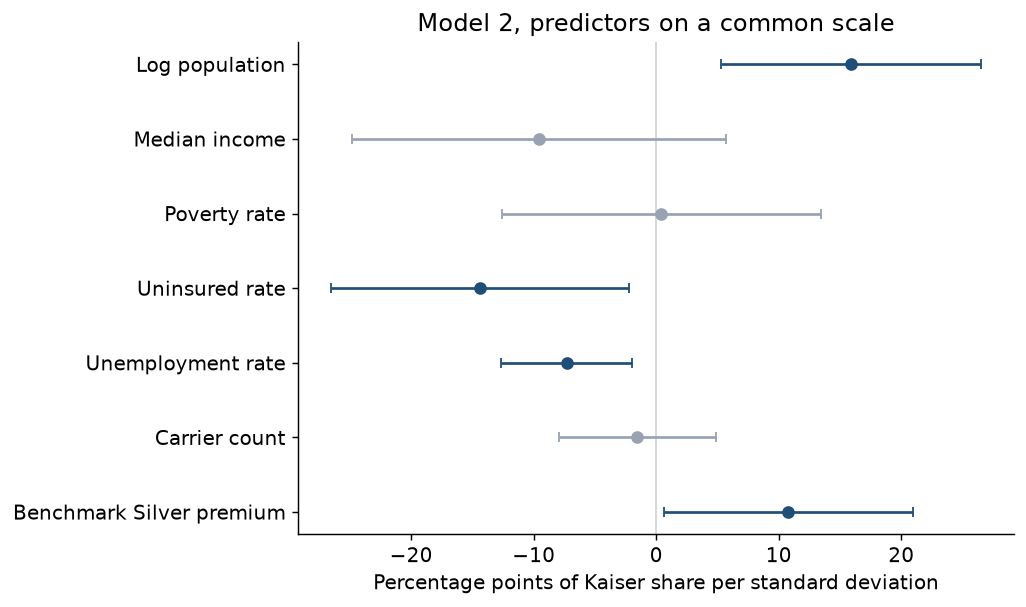

In [6]:
standardized = premium_counties.copy()
for column in MODEL_2:
    standardized[column] = (
        (premium_counties[column] - premium_counties[column].mean())
        / premium_counties[column].std(ddof=0)
    )
standardized_fit = fit_terms(
    "kp_market_share ~ log_population + income_10k + poverty_rate + uninsured_rate "
    "+ unemployment_rate + carrier_count + benchmark_silver_premium",
    standardized,
)

order = list(MODEL_2)
estimates = standardized_fit.params.loc[order].to_numpy() * 100
bounds = standardized_fit.conf_int().loc[order].to_numpy() * 100
positions = np.arange(len(order))[::-1]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.axvline(0, color="#d0d5dd", linewidth=1)
for estimate, (low, high), position in zip(estimates, bounds, positions):
    color = "#1f4e79" if low > 0 or high < 0 else "#98a2b3"
    ax.errorbar(
        estimate,
        position,
        xerr=[[estimate - low], [high - estimate]],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=3,
    )
ax.set_yticks(positions)
ax.set_yticklabels([LABELS[name] for name in order])
ax.set_xlabel("Percentage points of Kaiser share per standard deviation")
ax.set_title("Model 2, predictors on a common scale")
fig.tight_layout()


## What still lines up with share

Holding population constant, the socioeconomic associations from notebook 1 are each present on their own. Income and poverty drop out once the uninsured rate and the unemployment rate are in the same model. Those two still line up with share: higher uninsurance and higher unemployment go with lower Kaiser share. Log population stays positive. A larger offered county has higher share after the other terms.

Carrier count does not line up with share once population is held constant. The bivariate correlation in notebook 1 was county size.

A higher benchmark Silver premium lines up with higher share, and it remains in the joint model. Kaiser's gap to that benchmark also lines up with share on its own: where Kaiser is priced below the benchmark, share is higher. About a third of offered county-years are below, a third are exactly the benchmark, and a third are above. The gap and the benchmark move together, and entering both does not separate them. Model 2 is the specification to carry forward.

Gray intervals in the figure include zero. Blue intervals do not.


## Where these conditions sit now

Share is higher where the uninsured rate and unemployment are lower, and where the benchmark premium is higher. This section locates that pattern in the current footprint.

Share and the benchmark premium are 2025. The uninsured rate, unemployment, and population are 2024, the latest socioeconomic year. Counties are split at the median 2025 share among offered counties. Los Angeles has no benchmark premium.

2025 share,Counties,Mean share,Mean uninsured rate,Mean unemployment rate,Median population,Mean benchmark premium
At or above median,17,62%,4.6%,4.8%,"485,040",$624
Below median,16,17%,7.1%,7.3%,"658,081",$533


The median offered county has **34%** Kaiser share. The 17 counties at or above that line average **4.6%** uninsured and **4.8%** unemployed, with a benchmark premium of **$624**. The 16 counties below it average **7.1%** uninsured and **7.3%** unemployed, with a benchmark premium of **$533**. Median population is **485,040** above the line and **658,081** below it. Los Angeles, Orange, San Diego, and Riverside pull the below-median group toward larger counties. Population is not what separates the two groups.

county,share_group,share,enrollment,uninsured,unemployment,population,benchmark
Solano,At or above median,80.4%,"12,110",4.8%,4.9%,"451,918",$595
Alameda,At or above median,79.8%,"66,450",4.0%,4.4%,"1,649,473",$641
Contra Costa,At or above median,77.4%,"45,670",4.6%,4.5%,"1,165,012",$702
San Mateo,At or above median,73.0%,"24,380",3.8%,3.7%,"742,340",$722
San Joaquin,At or above median,72.9%,"31,130",6.3%,6.5%,"797,334",$545
Sonoma,At or above median,69.9%,"18,150",5.1%,4.1%,"485,040",$595
Napa,At or above median,69.5%,"4,480",5.7%,3.9%,"134,869",$595
Santa Cruz,At or above median,68.2%,"10,270",4.9%,5.9%,"264,926",$744
Sacramento,At or above median,60.7%,"41,490",4.9%,4.7%,"1,594,006",$601
Stanislaus,At or above median,59.7%,"14,430",5.6%,6.9%,"553,990",$545


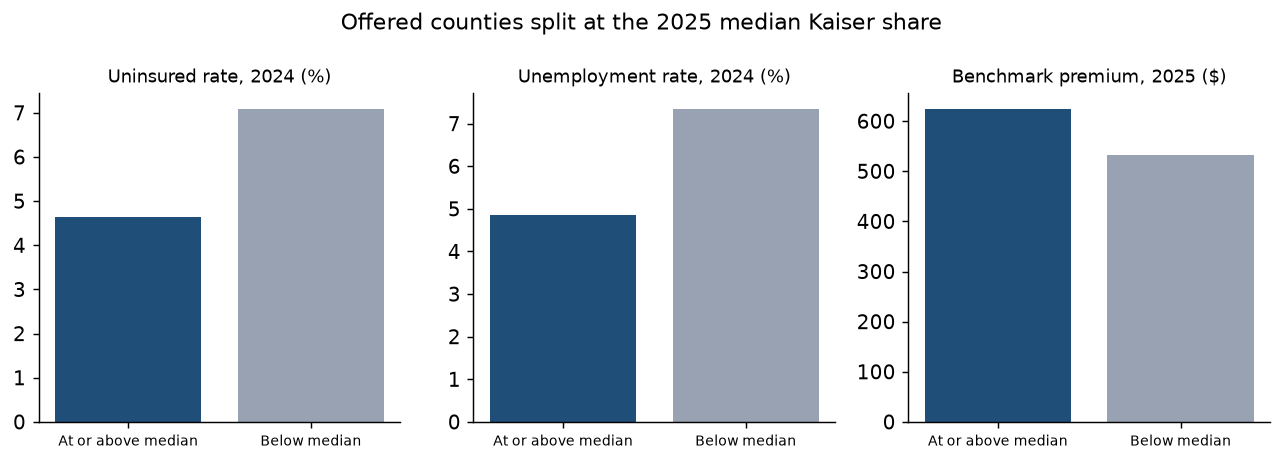

In [9]:
current = (
    market.loc[
        (market["year"] == 2025) & market["kp_offered"],
        ["county_fips", "county_name", "benchmark_silver_premium"],
    ]
    .merge(
        performance.loc[
            performance["year"] == 2025,
            ["county_fips", "kp_market_share", "kp_enrollment"],
        ],
        on="county_fips",
    )
    .merge(
        socioeconomic.loc[
            socioeconomic["year"] == 2024,
            ["county_fips", "population_total", "uninsured_rate", "unemployment_rate"],
        ],
        on="county_fips",
    )
)
median_share = current["kp_market_share"].median()
current["share_group"] = np.where(
    current["kp_market_share"] >= median_share,
    "At or above median",
    "Below median",
)

group_summary = (
    current.groupby("share_group", as_index=False)
    .agg(
        counties=("county_fips", "nunique"),
        mean_share=("kp_market_share", "mean"),
        mean_uninsured=("uninsured_rate", "mean"),
        mean_unemployment=("unemployment_rate", "mean"),
        median_population=("population_total", "median"),
        mean_benchmark=("benchmark_silver_premium", "mean"),
    )
)
group_order = ["At or above median", "Below median"]
group_summary["share_group"] = pd.Categorical(group_summary["share_group"], group_order, ordered=True)
group_summary = group_summary.sort_values("share_group")
summary_view = group_summary.copy()
summary_view["mean_share"] = (summary_view["mean_share"] * 100).map(lambda value: f"{value:.0f}%")
summary_view["mean_uninsured"] = summary_view["mean_uninsured"].map(lambda value: f"{value:.1f}%")
summary_view["mean_unemployment"] = summary_view["mean_unemployment"].map(lambda value: f"{value:.1f}%")
summary_view["median_population"] = summary_view["median_population"].map(lambda value: f"{value:,.0f}")
summary_view["mean_benchmark"] = summary_view["mean_benchmark"].map(lambda value: f"${value:,.0f}")
summary_view = summary_view.rename(columns={
    "share_group": "2025 share",
    "counties": "Counties",
    "mean_share": "Mean share",
    "mean_uninsured": "Mean uninsured rate",
    "mean_unemployment": "Mean unemployment rate",
    "median_population": "Median population",
    "mean_benchmark": "Mean benchmark premium",
})
display(HTML(summary_view.to_html(index=False)))

high = group_summary.loc[group_summary["share_group"].eq("At or above median")].iloc[0]
low = group_summary.loc[group_summary["share_group"].eq("Below median")].iloc[0]
display(Markdown(
    f"The median offered county has **{median_share:.0%}** Kaiser share. "
    f"The {int(high['counties'])} counties at or above that line average "
    f"**{high['mean_uninsured']:.1f}%** uninsured and **{high['mean_unemployment']:.1f}%** unemployed, "
    f"with a benchmark premium of **${high['mean_benchmark']:,.0f}**. "
    f"The {int(low['counties'])} counties below it average "
    f"**{low['mean_uninsured']:.1f}%** uninsured and **{low['mean_unemployment']:.1f}%** unemployed, "
    f"with a benchmark premium of **${low['mean_benchmark']:,.0f}**. "
    f"Median population is **{high['median_population']:,.0f}** above the line and "
    f"**{low['median_population']:,.0f}** below it. "
    "Los Angeles, Orange, San Diego, and Riverside pull the below-median group toward larger counties. "
    "Population is not what separates the two groups."
))

ranked = current.sort_values("kp_market_share", ascending=False).copy()
ranked_view = pd.DataFrame({
    "county": ranked["county_name"].str.replace(" County", "", regex=False),
    "share_group": ranked["share_group"],
    "share": (ranked["kp_market_share"] * 100).map(lambda value: f"{value:.1f}%"),
    "enrollment": ranked["kp_enrollment"].map(lambda value: f"{value:,.0f}"),
    "uninsured": ranked["uninsured_rate"].map(lambda value: f"{value:.1f}%"),
    "unemployment": ranked["unemployment_rate"].map(lambda value: f"{value:.1f}%"),
    "population": ranked["population_total"].map(lambda value: f"{value:,.0f}"),
    "benchmark": ranked["benchmark_silver_premium"].map(
        lambda value: "" if pd.isna(value) else f"${value:,.0f}"
    ),
})
display(HTML(ranked_view.to_html(index=False)))

fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
panel_specs = [
    ("mean_uninsured", "Uninsured rate, 2024 (%)"),
    ("mean_unemployment", "Unemployment rate, 2024 (%)"),
    ("mean_benchmark", "Benchmark premium, 2025 ($)"),
]
colors = ["#1f4e79", "#98a2b3"]
labels = ["At or above median", "Below median"]
for ax, (column, title) in zip(axes, panel_specs):
    ax.bar(labels, group_summary[column], color=colors)
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Offered counties split at the 2025 median Kaiser share", fontsize=12)
fig.tight_layout()


## Limits of this specification

The sample is the counties where Kaiser was offered. Intervals describe that cross-section. They are not a forecast, and a county fixed effect would remove the comparison this question is about, which is between places rather than change inside one county.

Offered includes counties where the service area covers only some ZIP codes. The premium is an age-40 individual rate. Los Angeles is omitted wherever a premium is required.
